In [5]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(1)
size = 5
moves = [(-1, 0), (1, 0), (0, -1), (0, 1)]   # up, down, left, right
arrows = ["^", "v", "<", ">"]

def step(state, action, goal):
    r, c = state
    dr, dc = moves[action]
    r = min(max(r + dr, 0), size - 1)
    c = min(max(c + dc, 0), size - 1)
    new_state = (r, c)
    if new_state == goal:
        return new_state, 1.0, True       # reached the goal: reward
    return new_state, -0.01, False        # every other step costs a little

In [6]:
alpha, gamma, eps = 0.5, 0.95, 0.1   # learning speed, value of the future, exploring

def train(Q, goal, episodes):
    steps_list = []
    for ep in range(episodes):
        state = (0, 0)
        steps = 0
        done = False
        while not done and steps < 300:
            if rng.random() < eps:
                a = rng.integers(4)                                # explore
            else:
                best = np.flatnonzero(Q[state] == Q[state].max())
                a = rng.choice(best)                               # use what it knows
            new_state, reward, done = step(state, a, goal)
            Q[state][a] += alpha * (reward + gamma * Q[new_state].max() - Q[state][a])
            state = new_state
            steps += 1
        steps_list.append(steps)
    return steps_list

Q = np.zeros((size, size, 4))
phase1 = train(Q, goal=(4, 4), episodes=150)    # goal bottom-right
Q_after_1 = Q.copy()
phase2 = train(Q, goal=(0, 4), episodes=400)    # goal moved to top-right

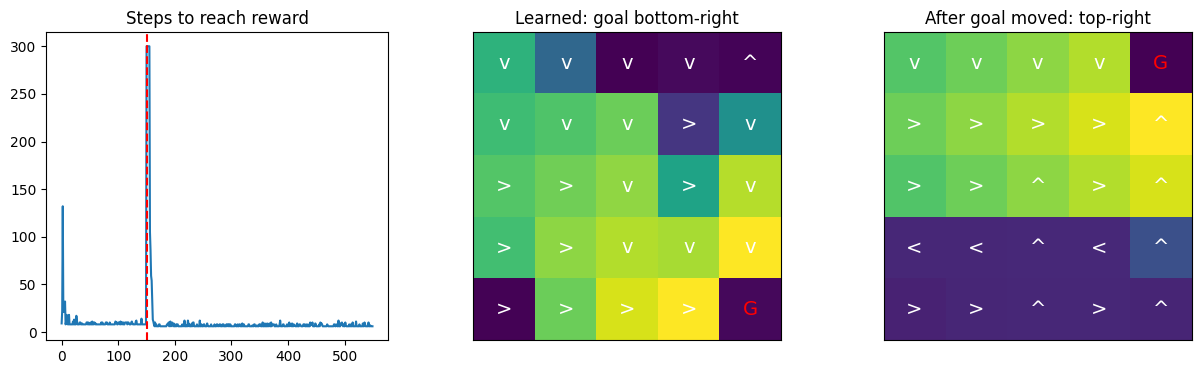

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
ax[0].plot(phase1 + phase2)
ax[0].axvline(150, color="red", linestyle="--")
ax[0].set_title("Steps to reach reward")

def show_policy(a, Qm, goal, title):
    a.imshow(Qm.max(axis=2), cmap="viridis")
    for r in range(size):
        for c in range(size):
            if (r, c) == goal:
                a.text(c, r, "G", ha="center", va="center", color="red", fontsize=14)
            else:
                a.text(c, r, arrows[int(np.argmax(Qm[r, c]))],
                       ha="center", va="center", color="white", fontsize=14)
    a.set_title(title)
    a.set_xticks([]); a.set_yticks([])

show_policy(ax[1], Q_after_1, (4, 4), "Learned: goal bottom-right")
show_policy(ax[2], Q, (0, 4), "After goal moved: top-right")
plt.show()